# Milestone 5 - Statistical Analysis
**Author:** Stephen Omengo Owuor

Hypothesis tests and confidence intervals on six business questions, with the assumptions of each test checked before it is used.

**Approach**
- Significance level 5% (two-sided). Every test reports a p-value, a confidence interval or effect size, and a plain-language conclusion.
- Assumptions are checked first (normality, equal variance, expected counts). When normality fails I use a robust or non-parametric test and report both.
- With 6 independent headline tests, the p-values are adjusted for multiple testing (Holm) at the end (tests 2a and 2b answer the same question, so only 2b enters the correction).
- The data is synthetic. A non-significant result means the simulation contains no such effect, and is not a claim about real retail.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy import stats
import statsmodels.formula.api as smf
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.multitest import multipletests

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlesize": 12, "axes.titleweight": "bold", "axes.grid": True, "grid.alpha": 0.25})
BLUE, ORANGE, GREY = "#1F5FA8", "#E07B00", "#9AA5B1"
FIG = Path("figures"); FIG.mkdir(exist_ok=True)
def save(name): plt.tight_layout(); plt.savefig(FIG / f"{name}.png", bbox_inches="tight"); plt.show()

d = pd.read_csv("../data/clean/sales_clean.csv", parse_dates=["date"], low_memory=False)
infl = pd.read_csv("../data/raw/kenya_inflation_monthly.csv")
tx = (d.groupby("transaction_id").agg(date=("date", "first"), basket=("revenue", "sum"), payment=("payment_method", "first"),
      location=("location_type", "first"), year_month=("year_month", "first")).reset_index())
daily = (d.groupby("date").agg(revenue=("revenue", "sum"), weekend=("is_weekend", "first"), payday=("is_payday_window", "first"),
         holiday=("is_holiday", "first"), school=("is_school_opening", "first")).reset_index())
daily["december"] = daily.date.dt.month == 12

results = []   # collected for the summary table
def add(name, p, effect): results.append(dict(test=name, p_value=p, effect=effect))

def welch(a, b):
    a, b = np.asarray(a, float), np.asarray(b, float)
    diff = a.mean() - b.mean()
    va, vb = a.var(ddof=1) / len(a), b.var(ddof=1) / len(b)
    se = np.sqrt(va + vb)
    df = (va + vb) ** 2 / (va ** 2 / (len(a) - 1) + vb ** 2 / (len(b) - 1))
    t = stats.t.ppf(0.975, df)
    pooled = np.sqrt(((len(a) - 1) * a.var(ddof=1) + (len(b) - 1) * b.var(ddof=1)) / (len(a) + len(b) - 2))
    p = stats.ttest_ind(a, b, equal_var=False).pvalue
    return dict(diff=diff, lo=diff - t * se, hi=diff + t * se, p=p, d=diff / pooled)
print(len(d), "lines;", len(tx), "baskets;", len(daily), "days")

302076 lines; 112202 baskets; 731 days


## Test 1 - Do weekends bring in more revenue than weekdays?
**H0:** average daily revenue is the same on weekends and weekdays. **H1:** it differs.

Daily revenue is a continuous measure, so a two-sample t-test is the natural choice. First check its assumptions.

Shapiro-Wilk normality p-values  weekend: 0.0002  weekday: 3.99e-12
Levene equal-variance p-value: 0.088
Skewness  weekend: 0.69  weekday: 0.92


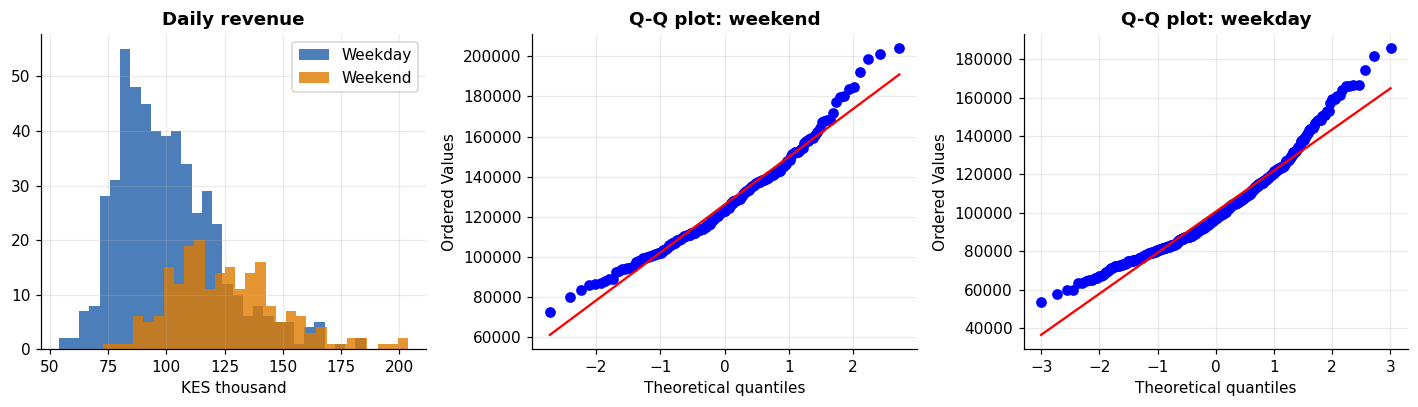

In [2]:
we = daily[daily.weekend].revenue; wd = daily[~daily.weekend].revenue
print("Shapiro-Wilk normality p-values  weekend:", f"{stats.shapiro(we).pvalue:.4f}", " weekday:", f"{stats.shapiro(wd).pvalue:.2e}")
print("Levene equal-variance p-value:", round(stats.levene(we, wd).pvalue, 3))
print("Skewness  weekend:", round(stats.skew(we), 2), " weekday:", round(stats.skew(wd), 2))

fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))
ax[0].hist(wd / 1e3, bins=30, color=BLUE, alpha=0.8, label="Weekday"); ax[0].hist(we / 1e3, bins=30, color=ORANGE, alpha=0.8, label="Weekend")
ax[0].set_title("Daily revenue"); ax[0].set_xlabel("KES thousand"); ax[0].legend()
stats.probplot(we, plot=ax[1]); ax[1].set_title("Q-Q plot: weekend")
stats.probplot(wd, plot=ax[2]); ax[2].set_title("Q-Q plot: weekday")
save("01_weekend_assumptions")

**Reading the checks:** the Shapiro test rejects normality, and the plots show a right skew caused by the December peak. With about 200 weekend days and 500 weekday days the t-test is still reliable (central limit theorem), and Levene shows similar variances. I use the **Welch t-test** (does not assume equal variances) and confirm it with the **Mann-Whitney test**, which makes no normality assumption.

In [3]:
r = welch(we, wd)
mw = stats.mannwhitneyu(we, wd)
print(f"Weekend mean: KES {we.mean():,.0f}   Weekday mean: KES {wd.mean():,.0f}")
print(f"Difference: KES {r['diff']:,.0f}  (95% CI {r['lo']:,.0f} to {r['hi']:,.0f})  = {r['diff']/wd.mean():+.1%}")
print(f"Welch t-test p = {r['p']:.2e};  Mann-Whitney p = {mw.pvalue:.2e};  Cohen's d = {r['d']:.2f}")
add("1. Weekend vs weekday revenue (Welch)", r["p"], f"{r['diff']/wd.mean():+.0%} daily revenue")

Weekend mean: KES 126,022   Weekday mean: KES 100,625
Difference: KES 25,397  (95% CI 21,628 to 29,166)  = +25.2%
Welch t-test p = 7.48e-33;  Mann-Whitney p = 6.21e-36;  Cohen's d = 1.13


**Is it really the weekend?** Weekends overlap with paydays, holidays and December, so I also fit a regression on log revenue with all of these at once. The coefficients give each effect while holding the others fixed (robust standard errors).

In [4]:
m = smf.ols("np.log(revenue) ~ weekend + payday + holiday + december + school", data=daily.astype({c: int for c in ["weekend", "payday", "holiday", "december", "school"]})).fit(cov_type="HC3")
eff = pd.DataFrame({"effect_%": (np.exp(m.params) - 1) * 100, "ci_low_%": (np.exp(m.conf_int()[0]) - 1) * 100,
                    "ci_high_%": (np.exp(m.conf_int()[1]) - 1) * 100, "p_value": m.pvalues}).drop("Intercept").round(3)
print(eff)
print("\nR-squared:", round(m.rsquared, 3))
print("Durbin-Watson (about 2 means no autocorrelation):", round(durbin_watson(m.resid), 2))
print("Breusch-Pagan heteroscedasticity p-value:", round(het_breuschpagan(m.resid, m.model.exog)[1], 3))

          effect_%  ci_low_%  ci_high_%  p_value
weekend     26.055    23.211     28.964      0.0
payday      27.443    24.467     30.491      0.0
holiday     18.472     9.066     28.690      0.0
december    29.961    25.570     34.506      0.0
school      13.065     8.976     17.307      0.0

R-squared: 0.591
Durbin-Watson (about 2 means no autocorrelation): 1.68
Breusch-Pagan heteroscedasticity p-value: 0.27


## Test 2 - Did promotions increase sales?
**H0:** promotions do not change the quantity sold. **H1:** they do.

Two angles. (a) Across all receipt lines, is quantity per line different on promotion? (b) A fairer comparison: for each product, compare its average **daily units** and **daily net revenue** on days it was on promotion against its other days (a paired design, so each product is compared with itself).

In [5]:
q1, q0 = d[d.has_promo].quantity, d[~d.has_promo].quantity
r = welch(q1, q0)
print(f"(a) Lines on promotion: {len(q1):,} (mean qty {q1.mean():.3f})   Not on promotion: {len(q0):,} (mean qty {q0.mean():.3f})")
print(f"    Difference {r['diff']:+.3f} units (95% CI {r['lo']:+.3f} to {r['hi']:+.3f}); Welch p = {r['p']:.3f}; Mann-Whitney p = {stats.mannwhitneyu(q1, q0).pvalue:.3f}")

(a) Lines on promotion: 18,176 (mean qty 1.606)   Not on promotion: 283,900 (mean qty 1.599)
    Difference +0.007 units (95% CI -0.004 to +0.019); Welch p = 0.219; Mann-Whitney p = 0.202


In [6]:
promos = pd.read_csv("../data/raw/promotions.csv", parse_dates=["start_date", "end_date"])
prods = pd.read_csv("../data/raw/products.csv")
dates = pd.date_range("2023-07-01", "2025-06-30")
on_promo = pd.DataFrame(False, index=dates, columns=prods.product_id)
for p in promos.itertuples():
    ids = prods.product_id[prods.category == p.target] if p.scope == "Category" else [p.target]
    on_promo.loc[p.start_date:p.end_date, list(ids)] = True

units = d.pivot_table(index="date", columns="product_id", values="quantity", aggfunc="sum", fill_value=0).reindex(index=dates, columns=prods.product_id, fill_value=0)
net = d.pivot_table(index="date", columns="product_id", values="revenue", aggfunc="sum", fill_value=0).reindex(index=dates, columns=prods.product_id, fill_value=0)

days_on = on_promo.sum()
keep = days_on[days_on >= 10].index          # products with at least 10 promotion days
pp = pd.DataFrame({"units_promo": [units[c][on_promo[c]].mean() for c in keep], "units_normal": [units[c][~on_promo[c]].mean() for c in keep],
                   "rev_promo": [net[c][on_promo[c]].mean() for c in keep], "rev_normal": [net[c][~on_promo[c]].mean() for c in keep]}, index=keep)
print(f"Products compared: {len(keep)} (each has 10+ promotion days)")
pp.mean().round(2)

Products compared: 88 (each has 10+ promotion days)


units_promo        6.73
units_normal       6.71
rev_promo        889.26
rev_normal      1028.65
dtype: float64

Daily units per product: promo 6.73 vs normal 6.71; mean difference +0.02 (95% CI -0.16 to +0.19); paired t p = 0.83; Wilcoxon p = 0.4; Shapiro on differences p = 2.1e-08
Daily net revenue per product (KES): promo 889.26 vs normal 1028.65; mean difference -139.39 (95% CI -191.21 to -87.57); paired t p = 7.1e-07; Wilcoxon p = 1.1e-11; Shapiro on differences p = 1.1e-10


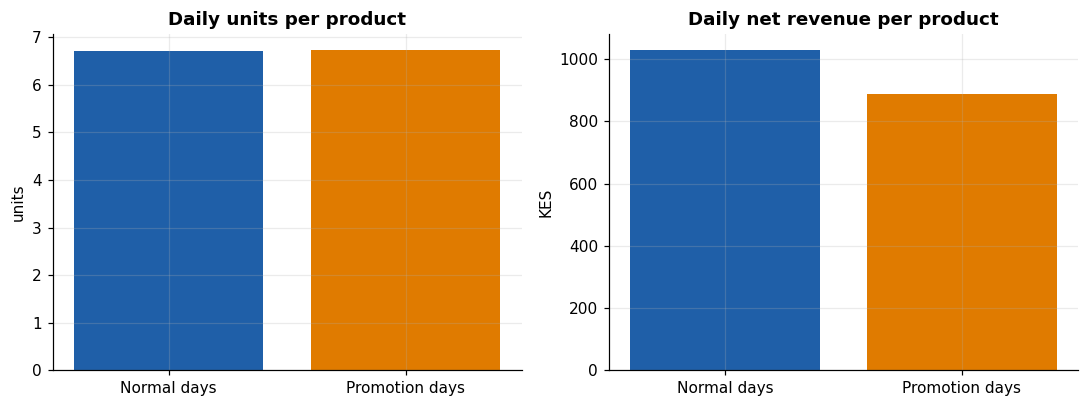

In [7]:
def paired(a, b):
    dlt = a - b; se = dlt.std(ddof=1) / np.sqrt(len(dlt)); t = stats.t.ppf(0.975, len(dlt) - 1)
    return dlt.mean(), dlt.mean() - t * se, dlt.mean() + t * se, stats.ttest_rel(a, b).pvalue, stats.wilcoxon(a, b).pvalue, stats.shapiro(dlt).pvalue

for label, a, b in [("Daily units per product", pp.units_promo, pp.units_normal), ("Daily net revenue per product (KES)", pp.rev_promo, pp.rev_normal)]:
    mean, lo, hi, p_t, p_w, p_sh = paired(a, b)
    print(f"{label}: promo {a.mean():.2f} vs normal {b.mean():.2f}; mean difference {mean:+.2f} (95% CI {lo:+.2f} to {hi:+.2f}); paired t p = {p_t:.2g}; Wilcoxon p = {p_w:.2g}; Shapiro on differences p = {p_sh:.2g}")
    if "units" in label: pu = (mean, lo, hi, p_w)
    else: pr = (mean, lo, hi, p_w, b.mean())
add("2a. Promotion: daily units per product (Wilcoxon)", pu[3], f"{pu[0]:+.2f} units/day")
add("2b. Promotion: daily net revenue per product (Wilcoxon)", pr[3], f"{pr[0]/pr[4]:+.0%} net revenue")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
for a_, (col1, col2, ttl, unit) in zip(ax, [("units_promo", "units_normal", "Daily units per product", "units"), ("rev_promo", "rev_normal", "Daily net revenue per product", "KES")]):
    a_.bar(["Normal days", "Promotion days"], [pp[col2].mean(), pp[col1].mean()], color=[BLUE, ORANGE]); a_.set_title(ttl); a_.set_ylabel(unit)
save("02_promotions")

**Assumption note:** the paired differences fail the normality check for revenue, so the Wilcoxon signed-rank test is the one to trust there, and I report it. It agrees with the paired t-test. A limit of this design: promotion days are not randomly chosen, so seasonality could still play a small part.

## Test 3 - Do M-Pesa customers spend more than cash customers?
**H0:** average basket value is the same for M-Pesa and cash. **H1:** it differs.

Basket = one transaction. The 87 baskets with unknown payment method are excluded (they are single-line baskets and would distort the comparison).

Skewness of basket value: 3.29 (raw) -0.34 (log)
Levene p: 0.376


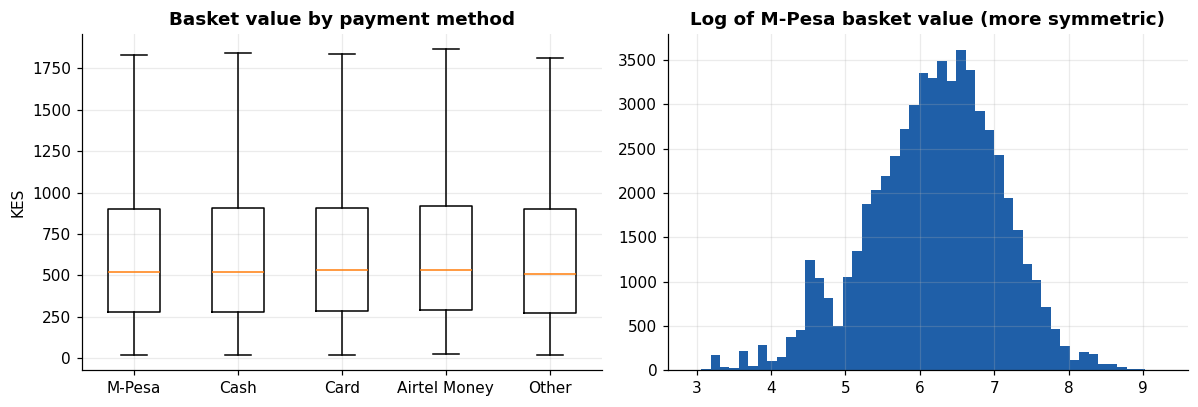

In [8]:
b = tx[tx.payment != "Unknown"]
mp, cs = b[b.payment == "M-Pesa"].basket, b[b.payment == "Cash"].basket
print("Skewness of basket value:", round(stats.skew(mp), 2), "(raw)", round(stats.skew(np.log(mp)), 2), "(log)")
print("Levene p:", round(stats.levene(mp, cs).pvalue, 3))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
order = ["M-Pesa", "Cash", "Card", "Airtel Money", "Other"]
ax[0].boxplot([b[b.payment == k].basket.clip(upper=b.basket.quantile(0.99)) for k in order], tick_labels=order, showfliers=False)
ax[0].set_title("Basket value by payment method"); ax[0].set_ylabel("KES")
ax[1].hist(np.log(mp), bins=50, color=BLUE); ax[1].set_title("Log of M-Pesa basket value (more symmetric)")
save("03_payment")

In [9]:
r = welch(mp, cs); rl = welch(np.log(mp), np.log(cs))
print(f"M-Pesa mean KES {mp.mean():.0f} vs Cash mean KES {cs.mean():.0f}")
print(f"Difference KES {r['diff']:+.1f} (95% CI {r['lo']:+.1f} to {r['hi']:+.1f}); Welch p = {r['p']:.3f}; Cohen's d = {r['d']:.3f}")
print(f"On the log scale: p = {rl['p']:.3f};  Mann-Whitney p = {stats.mannwhitneyu(mp, cs).pvalue:.3f}")
kw = stats.kruskal(*[g.basket for _, g in b.groupby("payment")])
print(f"All five payment methods (Kruskal-Wallis): H = {kw.statistic:.2f}, p = {kw.pvalue:.3f}")
add("3. M-Pesa vs cash basket value (Welch)", r["p"], f"{r['diff']:+.0f} KES per basket")

M-Pesa mean KES 702 vs Cash mean KES 704
Difference KES -2.5 (95% CI -11.8 to +6.8); Welch p = 0.597; Cohen's d = -0.004
On the log scale: p = 0.791;  Mann-Whitney p = 0.960
All five payment methods (Kruskal-Wallis): H = 3.83, p = 0.430


## Test 4 - Does inflation move with basket size?
**H0:** monthly average basket and Kenyan 12-month inflation are uncorrelated. **H1:** they are correlated.

With 24 monthly points, the test has low power, and both series can drift over time, which creates false correlations. So I test the levels and also the month-to-month changes.

Levels: Pearson r = -0.20 (95% CI -0.56 to 0.22), p = 0.347;  Spearman rho = -0.12, p = 0.574


Month-to-month changes: r = -0.09, p = 0.675
With n = 24, only correlations beyond about |r| = 0.54 could be detected reliably (80% power).


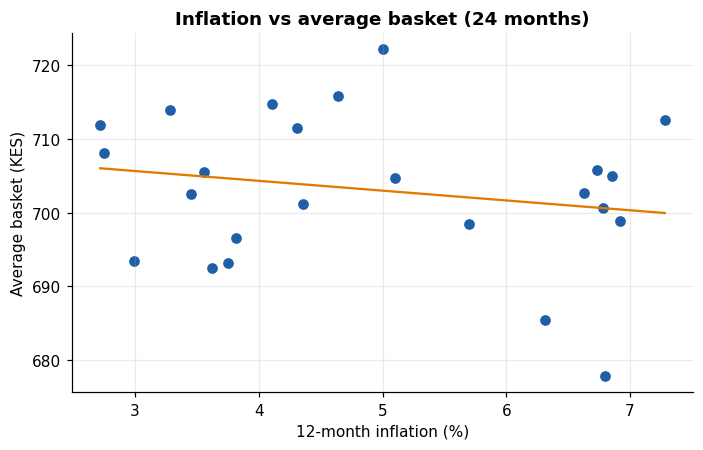

In [10]:
mb = tx.groupby("year_month").basket.mean().rename("avg_basket").reset_index().merge(infl, left_on="year_month", right_on="month")
x, y = mb.twelve_month_inflation, mb.avg_basket
r, p = stats.pearsonr(x, y); rho, p_s = stats.spearmanr(x, y)
n = len(mb); z = np.arctanh(r); lo, hi = np.tanh(z - 1.96 / np.sqrt(n - 3)), np.tanh(z + 1.96 / np.sqrt(n - 3))
r_d, p_d = stats.pearsonr(x.diff().dropna(), y.diff().dropna())
print(f"Levels: Pearson r = {r:.2f} (95% CI {lo:.2f} to {hi:.2f}), p = {p:.3f};  Spearman rho = {rho:.2f}, p = {p_s:.3f}")
print(f"Month-to-month changes: r = {r_d:.2f}, p = {p_d:.3f}")
print(f"With n = {n}, only correlations beyond about |r| = {np.tanh((1.96 + 0.84) / np.sqrt(n - 3)):.2f} could be detected reliably (80% power).")

fig, ax = plt.subplots(figsize=(6.5, 4.2))
ax.scatter(x, y, color=BLUE); m_, c_ = np.polyfit(x, y, 1); xs = np.linspace(x.min(), x.max(), 50); ax.plot(xs, m_ * xs + c_, color=ORANGE)
ax.set_xlabel("12-month inflation (%)"); ax.set_ylabel("Average basket (KES)"); ax.set_title("Inflation vs average basket (24 months)")
save("04_inflation")
add("4. Inflation vs average basket (Pearson)", p, f"r = {r:.2f}")

## Test 5 - Do loyalty tiers differ in customer spending?
**H0:** total spend per customer is the same across Basic, Silver and Gold. **H1:** at least one tier differs.

Spend per customer is very right-skewed (a few big spenders), so the rank-based **Kruskal-Wallis** test is the primary test, with ANOVA as a comparison.

              customers     mean  median
loyalty_tier                            
Basic              3043   8543.0  4448.0
Gold                502   7689.0  4168.0
Silver             1346  11890.0  4414.0

Skewness of spend per customer: 48.93 | Levene p: 0.102
Kruskal-Wallis p = 0.300 (epsilon-squared = 0.0005);  ANOVA p = 0.108


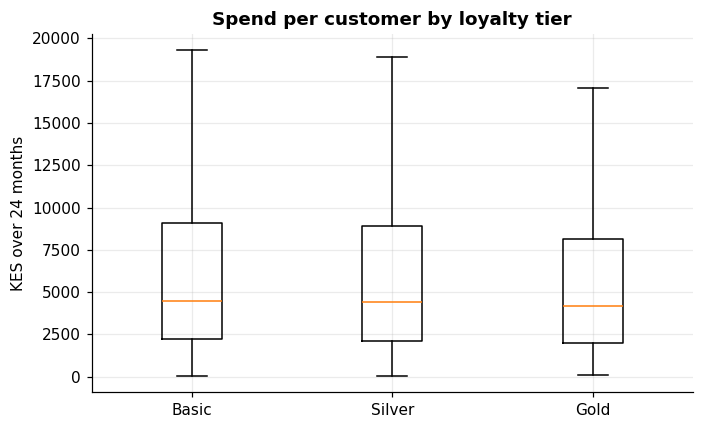

In [11]:
cu = d.dropna(subset=["customer_id"]).groupby(["customer_id", "loyalty_tier"]).revenue.sum().reset_index()
groups = [g.revenue for _, g in cu.groupby("loyalty_tier")]
print(cu.groupby("loyalty_tier").revenue.agg(customers="count", mean="mean", median="median").round(0))
print("\nSkewness of spend per customer:", round(stats.skew(cu.revenue), 2), "| Levene p:", round(stats.levene(*groups).pvalue, 3))
kw = stats.kruskal(*groups); an = stats.f_oneway(*groups)
eta2 = kw.statistic / (len(cu) - 1)
print(f"Kruskal-Wallis p = {kw.pvalue:.3f} (epsilon-squared = {eta2:.4f});  ANOVA p = {an.pvalue:.3f}")

order = ["Basic", "Silver", "Gold"]
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.boxplot([cu[cu.loyalty_tier == t].revenue.clip(upper=cu.revenue.quantile(0.99)) for t in order], tick_labels=order, showfliers=False)
ax.set_title("Spend per customer by loyalty tier"); ax.set_ylabel("KES over 24 months")
save("05_loyalty")
add("5. Loyalty tier vs spend per customer (Kruskal-Wallis)", kw.pvalue, f"epsilon-sq = {eta2:.4f}")

## Test 6 - Is payment method related to store location type?
**H0:** payment method and location type (urban, peri-urban, rural) are independent. **H1:** they are associated.

A chi-square test of independence needs every expected count to be at least 5, which I check first.

In [12]:
ct = pd.crosstab(b.payment, b.location)
chi2, p, dof, exp = stats.chi2_contingency(ct)
v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
print(ct); print("\nSmallest expected count:", round(exp.min(), 1), "(needs to be 5 or more)")
print(f"chi-square = {chi2:.2f}, df = {dof}, p = {p:.3f}, Cramer's V = {v:.3f}")
share = pd.crosstab(b.payment, b.location, normalize="columns").round(3) * 100
print("\nPayment share within each location type (%):"); print(share)
add("6. Payment method vs location type (chi-square)", p, f"Cramer's V = {v:.3f}")

location      Peri-urban  Rural  Urban
payment                               
Airtel Money         955    267   3311
Card                3322    839  11397
Cash                6662   1671  22886
M-Pesa             12273   3180  43115
Other                455    116   1666

Smallest expected count: 121.2 (needs to be 5 or more)
chi-square = 5.68, df = 8, p = 0.683, Cramer's V = 0.005

Payment share within each location type (%):
location      Peri-urban  Rural  Urban
payment                               
Airtel Money         4.0    4.4    4.0
Card                14.0   13.8   13.8
Cash                28.1   27.5   27.8
M-Pesa              51.9   52.4   52.3
Other                1.9    1.9    2.0


## Summary of all tests

In [13]:
res = pd.DataFrame(results)
# Holm correction across the independent headline tests (2a and 2b answer the same question, so use 2b)
res["p_value"] = res.p_value.astype(float)
use = ~res.test.str.startswith("2a")
adj = pd.Series(np.nan, index=res.index)
adj[use] = multipletests(res.p_value[use], method="holm")[1]
res["holm_adjusted_p"] = adj
res["significant_at_5%"] = np.where(res.holm_adjusted_p < 0.05, "Yes", np.where(res.holm_adjusted_p.isna(), "(see 2b)", "No"))
res["p_value"] = res.p_value.map(lambda v: f"{v:.2g}"); res["holm_adjusted_p"] = res.holm_adjusted_p.map(lambda v: "" if pd.isna(v) else f"{v:.2g}")
res.to_csv("test_summary.csv", index=False)
res

,test,p_value,effect,holm_adjusted_p,significant_at_5%
0,1. Weekend vs weekday revenue (Welch),7.5e-33,+25% daily revenue,4.5e-32,Yes
1,2a. Promotion: daily units per product (Wilcoxon),0.4,+0.02 units/day,,(see 2b)
2,2b. Promotion: daily net revenue per product (...,1.1e-11,-14% net revenue,5.4e-11,Yes
3,3. M-Pesa vs cash basket value (Welch),0.6,-3 KES per basket,1,No
4,4. Inflation vs average basket (Pearson),0.35,r = -0.20,1,No
5,5. Loyalty tier vs spend per customer (Kruskal...,0.3,epsilon-sq = 0.0005,1,No
6,6. Payment method vs location type (chi-square),0.68,Cramer's V = 0.005,1,No


## Conclusions in plain language
Write your own conclusion for each test after reading the outputs above: what the question was, what the result is (with the number), and what a manager should do.

1. Weekend vs weekday:
2. Promotions:
3. M-Pesa vs cash:
4. Inflation and basket size:
5. Loyalty tiers:
6. Payment method and location:

**Limits to state:** the data is simulated; non-significant results mean no effect was found in this dataset, not that none exists in real stores; promotion days were not randomised.